In [ ]:
import tarfile
import gzip
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import scipy
import warnings
from numpy.polynomial import Polynomial
from scipy.signal import savgol_filter, find_peaks
from scipy.optimize import curve_fit
from scipy.optimize import minimize_scalar
import requests
from pathlib import Path
from IPython.display import display
from scipy.optimize import linear_sum_assignment

In [3]:
descargas = {
    "J_PASP_107_1042.tar.gz": "https://cdsarc.cds.unistra.fr/viz-bin/nph-Cat/tar.gz?J/PASP/107/1042",
    "J_ApJS_94_221.tar.gz":   "https://cdsarc.cds.unistra.fr/viz-bin/nph-Cat/tar.gz?J/ApJS/94/221",
}

for nombre, url in descargas.items():
    r = requests.get(url, timeout=120)
    r.raise_for_status()
    with open(nombre, "wb") as f:
        f.write(r.content)
    print(f"{nombre}: listo ({len(r.content)/1e6:.1f} MB)")

J_PASP_107_1042.tar.gz: listo (9.0 MB)
J_ApJS_94_221.tar.gz: listo (0.5 MB)


In [4]:
tar = tarfile.open("J_PASP_107_1042.tar.gz","r:*")
tar.extractall("espectros", filter='data')

tar2 = tarfile.open("J_ApJS_94_221.tar.gz","r:*")
tar2.extractall("lineas", filter='data')

In [5]:
spectral_files = [
    name for name in tar.getnames()
    if "ab" in name and name.endswith(".gz")
]

print(len(spectral_files))

310


In [6]:
all_spectra = []

for file_name in spectral_files:

    file = tar.extractfile(file_name)

    with gzip.open(file, 'rt') as f:
        df = pd.read_csv(
            f,
            sep=r'\s+',
            header=None
        )


    temp = pd.DataFrame({
        "wavenumber": df[0],
        "intensity": df[1]
    })

    all_spectra.append(temp)

Sabemos que $$\lambda =
\frac{1}{\tilde{\nu}}$$

Y $$1 cm = 10^{8} Å$$

In [7]:
spectra = pd.concat(all_spectra)

spectra = spectra.drop_duplicates(
    subset="wavenumber"
)


spectra.head()

spectra["lambda"] = 1e8 / spectra["wavenumber"]

spectra = spectra.sort_values("lambda")

print(spectra)

      wavenumber  intensity        lambda
1420    10953.40    0.57325   9129.585334
1419    10953.36    0.56870   9129.618674
1418    10953.32    0.58553   9129.652014
1417    10953.28    0.62694   9129.685355
1416    10953.24    0.65616   9129.718695
...          ...        ...           ...
4        1866.04    0.00000  53589.419305
3        1866.03    0.00000  53589.706489
2        1866.02    0.00000  53589.993676
1        1866.01    0.00000  53590.280867
0        1866.00    0.00000  53590.568060

[347034 rows x 3 columns]


In [8]:
spectra["wavenumber"] = pd.to_numeric(spectra["wavenumber"], errors='coerce')
spectra["intensity"] = pd.to_numeric(spectra["intensity"], errors='coerce')
spectra = spectra.dropna(subset=["wavenumber", "intensity"])

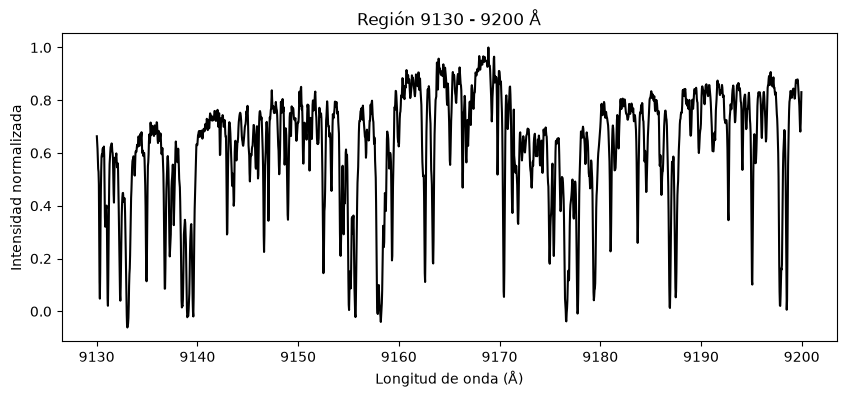

In [9]:
lambdai = 9130
lambdaf = 9200

region = spectra[
    (spectra["lambda"] > lambdai) &
    (spectra["lambda"] < lambdaf)
]

plt.figure(figsize=(10,4))

plt.plot(
    region["lambda"],
    region["intensity"],
    color="black"
)

plt.xlabel("Longitud de onda (Å)")
plt.ylabel("Intensidad normalizada")

plt.title(f"Región {lambdai} - {lambdaf} Å")

plt.show()

In [10]:
file = tar2.extractfile("./table2.gz")
with gzip.open(file,'rt') as f:

    lines = pd.read_fwf(
        f,
        colspecs=[
            (0,4),      # Num
            (5,15),     # Term1
            (15,16),    # -
            (16,26),    # Term2
            (27,28),    # J1
            (28,29),    # -
            (29,30),    # J2
            (30,36),    # I
            (37,47),    # Lvac
            (48,58),    # Lair
            (59,65),    # Lo-R
            (65,75),    # Sigma
            (76,77),    # q_Sigma
            (79,83),    # So-R
            (84,89),    # El
            (90,95),    # Eu
            (96,105),   # Elc
            (106,115),  # Euc
            (116,122),  # loggf
            (123,124),  # source
            (126,131)   # Blend
        ]
    )

lines.columns = [
"Num","Term1","dash1","Term2","J1","dash2","J2",
"I","Lvac","Lair","LoR","Sigma","qSigma","SoR",
"El","Eu","Elc","Euc","loggf","source","Blend"
]

 En el catálogo dice que las unidades de Lvac están en 0.1nm = 1Å, así que no hay que convertir nada. Usamos Lvacío porque con los datos de Hinkle se usó un interferómetro de transformada de Fourier.

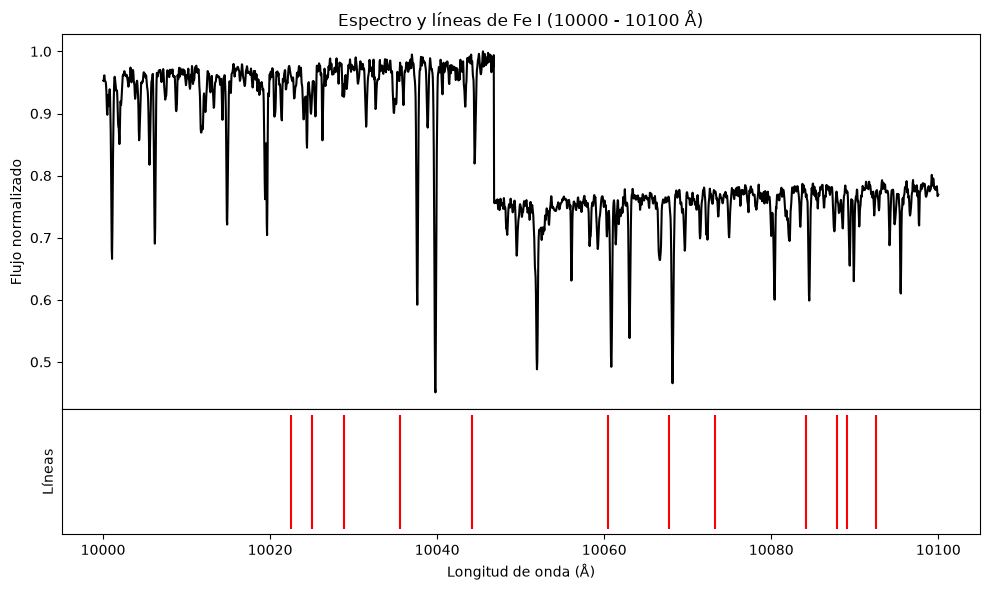

In [11]:
lines["lambda"] = lines["Lvac"]

fe_lines = lines[
    lines["qSigma"] == "A"
]

lambda_min = 10000
lambda_max = 10100

copy_fe_lines = fe_lines.copy()
copy_fe_lines = copy_fe_lines[
    (copy_fe_lines["lambda"] > lambda_min) &
    (copy_fe_lines["lambda"] < lambda_max)
]

espectro = spectra.copy()
espectro = espectro[
    (espectro["lambda"] > lambda_min) &
    (espectro["lambda"] < lambda_max)
]

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 6), sharex=True, gridspec_kw={'height_ratios': [3, 1]})


ax1.plot(espectro["lambda"], espectro["intensity"], color="black")
ax1.set_ylabel("Flujo normalizado")
ax1.set_title(f"Espectro y líneas de Fe I ({lambda_min} - {lambda_max} Å)")


ax2.vlines(
    copy_fe_lines["lambda"],
    ymin=0,
    ymax=1,
    color="red"
)
ax2.set_ylabel("Líneas")
ax2.set_xlabel("Longitud de onda (Å)")
ax2.set_yticks([])


plt.tight_layout()
plt.subplots_adjust(hspace=0)
plt.show()

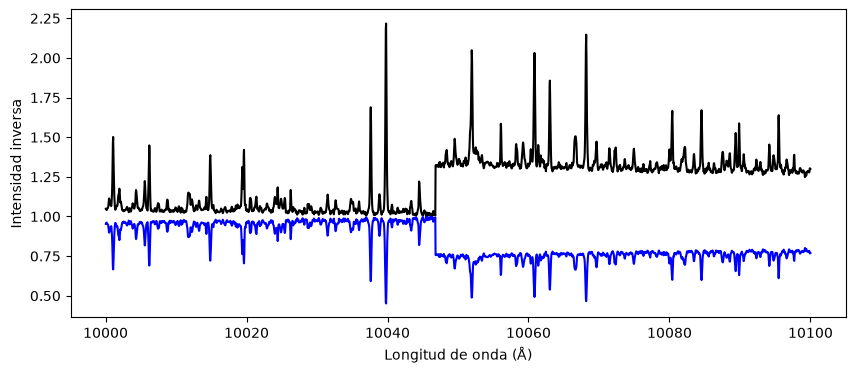

In [12]:
fe_lines = fe_lines.copy()
fe_lines["lambda"] = pd.to_numeric(
    fe_lines["Lvac"],
    errors="coerce"
)

fe_lines = fe_lines.dropna(
    subset=["lambda"]
).copy()


fe_lines = fe_lines.sort_values(
    "lambda"
).reset_index(drop=True)

intensidad_inversa = 1 / espectro["intensity"]
plt.figure(figsize=(10,4))
plt.plot(
    espectro["lambda"],
    intensidad_inversa,
    color="black"
)
plt.plot(
    espectro["lambda"],
    espectro["intensity"],
    color="blue",
)
plt.xlabel("Longitud de onda (Å)")
plt.ylabel("Intensidad inversa")
plt.show()

In [13]:
flujo_inverso = 1 / spectra["intensity"]
minimos = scipy.signal.find_peaks(flujo_inverso, prominence=0.05)
lambdas_minimos = spectra["lambda"].iloc[minimos[0]].values
intensidades_minimos = spectra["intensity"].iloc[minimos[0]].values

En la región: 9 catalogadas | 8 con mínimo cerca | 0 aceptadas | 1 ruido | 7 blends | 0 por corrimiento


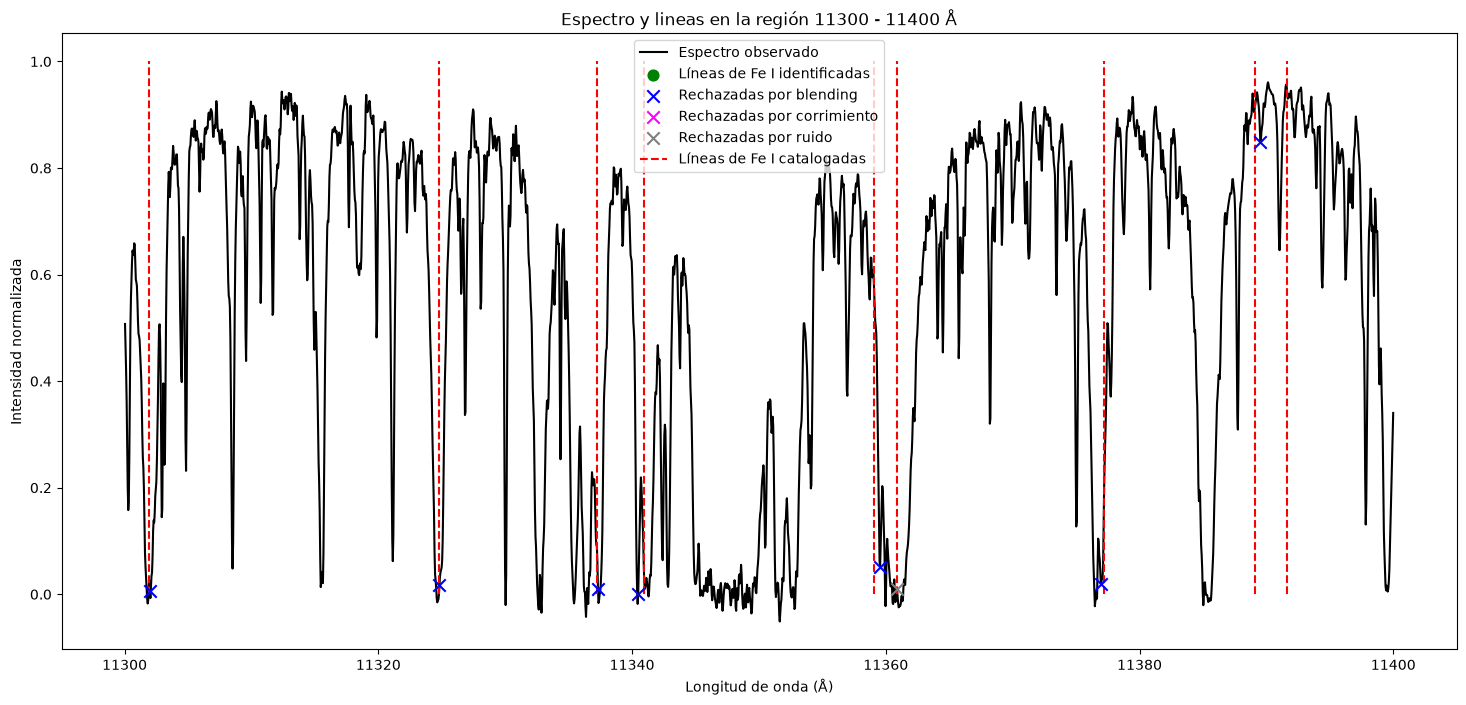

,lambda_catalogo,lambda_observada,desplazamiento_A,profundidad,estado
252,11301.955,11301.989150,0.034150,0.480411,blend: saturada
253,11324.779,11324.814129,0.035129,0.693062,blend: saturada
254,11337.247,11337.310613,0.063613,0.591202,blend: saturada
255,11340.912,11340.482449,-0.429551,0.729463,blend: saturada
256,11359.064,11359.548217,0.484217,0.553373,blend: mas de un valle
257,11360.845,11360.881350,0.036350,0.079017,ruido: muy pequena
258,11377.195,11376.952569,-0.242431,0.478607,blend: saturada
259,11389.066,11389.521640,0.455640,0.098472,blend: mas de un valle


In [43]:
def detector_lineas_fe(lambda_min,lambda_max):

    ventana_busqueda = 0.5
    identificaciones = []

    # --- parámetros ---
    prominencia_minimos = 0.05  # en 1/flujo
    fraccion_prominencia = 0.25 # un mínimo cercano al catálogo cuenta si tiene al menos esta fracción de la prominencia del más fuerte
    separacion_blend = 0.15     # Å, otra línea del catálogo más cerca que esto se funde con la nuestra
    ventana_minima = 1.0        # Å, semiancho mínimo de la ventana local para buscar valles vecinos (un doblete está a ~0.7 Å)
    fraccion_valle = 0.4        # un valle vecino cuenta como mezcla si es al menos esta fracción de la profundidad de la línea
    prominencia_vecina_max = 0.1 # ...pero en líneas muy profundas basta con que el vecino tenga esta prominencia (zonas apretadas)
    tolerancia_doblete = 0.1    # Å, el valle vecino es un doblete si está a la misma distancia que otra línea del catálogo, con esta tolerancia
    asimetria_max = 0.4         # las dos alas deben ser parecidas
    profundidad_asimetria = 0.1
    separacion_propia = 0.1     # Å, si la línea catalogada tiene su propio valle a menos de esto, pero lejos del mínimo que le tocó, es mezcla
    fraccion_propia = 0.4       # ...y si ese valle propio es al menos esta fracción de la profundidad del mínimo que le tocó, es mezcla aunque el flujo se recupere

    # 2) mezcla por saturación
    flujo_saturado = 0.05       # si el mínimo llega casi a cero la línea está saturada: casi siempre son varias líneas encimadas

    # 1) muy chiquita = ruido
    profundidad_minima = 0.08   # profundidad respecto al continuo local
    factor_ruido = 5            # y al menos este múltiplo del ruido del espectro

    # 3) y 4) corrimiento según la profundidad (contra lambda del catálogo)
    profundidad_debil = 0.25    # por debajo de esto la línea es débil
    profundidad_fuerte = 0.4    # por encima de esto la línea es fuerte
    corrimiento_fuerte_max = 0.15   # Å, una fuerte más corrida que esto no es confiable
    corrimiento_debil_min = 0.03    # Å, una débil con menos corrimiento que esto no es confiable


    # --- mínimos ---
    flujo_inverso = 1 / spectra["intensity"]
    minimos = scipy.signal.find_peaks(flujo_inverso, distance=1, prominence=prominencia_minimos)
    lambdas_minimos = spectra["lambda"].iloc[minimos[0]].values
    intensidades_minimos = spectra["intensity"].iloc[minimos[0]].values
    prominencias = minimos[1]["prominences"]

    lambda_espectro = spectra["lambda"].values
    flujo_espectro = spectra["intensity"].values
    ruido = 1.4826 * np.median(abs(np.diff(flujo_espectro) - np.median(np.diff(flujo_espectro)))) / np.sqrt(2)
    lambdas_catalogo = fe_lines["lambda"].values


    # --- candidatos de cada línea del catálogo: mínimos cercanos con prominencia razonable ---
    candidatos_linea = []
    for linea in lambdas_catalogo:
        izq = np.searchsorted(lambdas_minimos, linea - ventana_busqueda)
        der = np.searchsorted(lambdas_minimos, linea + ventana_busqueda)
        if der <= izq:
            candidatos_linea.append(np.array([], dtype=int))
            continue
        candidatos = np.arange(izq, der)
        candidatos_linea.append(candidatos[prominencias[candidatos] >= fraccion_prominencia * prominencias[candidatos].max()])

    # líneas del catálogo con candidatos que comparten mínimos se emparejan juntas (un doblete tiene dos líneas y dos mínimos)
    con_candidatos = [k for k in range(len(lambdas_catalogo)) if len(candidatos_linea[k]) > 0]
    grupos = []
    for k in con_candidatos:
        if grupos and candidatos_linea[k].min() <= candidatos_linea[grupos[-1][-1]].max():
            grupos[-1].append(k)
        else:
            grupos.append([k])

    asignado = {}
    for grupo in grupos:
        minimos_grupo = np.unique(np.concatenate([candidatos_linea[k] for k in grupo]))
        costo = np.full((len(grupo), len(minimos_grupo)), 1e3)
        for r, k in enumerate(grupo):
            columnas = np.searchsorted(minimos_grupo, candidatos_linea[k])
            costo[r, columnas] = abs(lambdas_minimos[candidatos_linea[k]] - lambdas_catalogo[k])
        filas, columnas = linear_sum_assignment(costo)
        for r, c in zip(filas, columnas):
            if costo[r, c] < 1e3:
                asignado[grupo[r]] = minimos_grupo[c]

    indices_minimos = []
    motivos = []
    for k in con_candidatos:
        if k in asignado:
            indices_minimos.append(asignado[k])
            motivos.append("ok")
        else:
            indices_minimos.append(candidatos_linea[k][np.argmin(abs(lambdas_minimos[candidatos_linea[k]] - lambdas_catalogo[k]))])
            motivos.append("sin minimo propio")
        identificaciones.append(lambdas_catalogo[k])

    identificaciones = np.array(identificaciones)
    indices_minimos = np.array(indices_minimos)
    motivos = np.array(motivos, dtype=object)
    valida = motivos == "ok"

    # otra línea del catálogo pegada a la nuestra: no se pueden separar
    for r, k in enumerate(con_candidatos):
        vecinas = np.delete(abs(lambdas_catalogo - lambdas_catalogo[k]), k)
        if valida[r] and len(vecinas) > 0 and vecinas.min() < separacion_blend:
            valida[r] = False
            motivos[r] = "blend: vecina en catalogo"


    # --- filtros, en este orden: 1) ruido, 2) mezcla (salvo doblete en Nave), 3) fuerte muy corrida, 4) débil casi sin corrimiento ---
    desplazamientos = np.zeros(len(identificaciones))
    profundidades = np.zeros(len(identificaciones))
    blends = np.array([m.startswith("blend") for m in motivos])
    dobletes = np.zeros(len(identificaciones), dtype=bool)

    for i in range(len(identificaciones)):
        linea = identificaciones[i]
        indice = indices_minimos[i]
        lambda_obs = lambdas_minimos[indice]
        intensidad = intensidades_minimos[indice]

        # continuo local (percentil alto en ±1 Å): el espectro no está en 1.0 exacto
        a = np.searchsorted(lambda_espectro, lambda_obs - 1.0)
        b = np.searchsorted(lambda_espectro, lambda_obs + 1.0)
        continuo = np.percentile(flujo_espectro[a:b], 90)

        desplazamientos[i] = lambda_obs - linea
        profundidades[i] = continuo - intensidad

        # 1) muy chiquita: es ruido
        if profundidades[i] < max(profundidad_minima, factor_ruido * ruido):
            valida[i] = False
            blends[i] = False
            motivos[i] = "ruido: muy pequena"
            continue
        if not valida[i]:
            continue

        # 2) mezcla: una línea que llega a cero está saturada, son varias líneas encimadas
        if intensidad <= flujo_saturado:
            blends[i] = True
            valida[i] = False
            motivos[i] = "blend: saturada"
            continue

        # 2) mezcla: ¿hay más valles alrededor de la línea?
        ventana_local = max(profundidades[i] * 0.5, ventana_minima)
        ini = np.searchsorted(lambda_espectro, lambda_obs - ventana_local)
        fin = np.searchsorted(lambda_espectro, lambda_obs + ventana_local)
        lambda_local = lambda_espectro[ini:fin]
        flujo_local = flujo_espectro[ini:fin]

        if len(flujo_local) < 5:
            valida[i] = False
            motivos[i] = "perfil incompleto"
            continue

        imin = np.argmin(abs(lambda_local - lambda_obs))

        umbral = max(min(fraccion_valle * profundidades[i], prominencia_vecina_max), 4 * ruido)
        valles = scipy.signal.find_peaks(-flujo_local, prominence=umbral)[0]
        valles = [v for v in valles if abs(v - imin) > 1]

        es_blend = False
        for v in valles:
            # si el otro valle está a la misma distancia que otra línea de Nave es un doblete y se queda; si no, es una mezcla
            separacion_valle = lambda_local[v] - lambda_obs
            otras = (abs((lambdas_catalogo - linea) - separacion_valle) <= tolerancia_doblete) & (abs(lambdas_catalogo - linea) > 1e-6)
            if otras.any():
                dobletes[i] = True
            else:
                es_blend = True

        # la línea catalogada tiene su propio valle cerca de su posición, lejos del mínimo que le tocó: ese mínimo puede ser de otra línea
        # es mezcla si el valle propio es importante (comparable al mínimo) o si el flujo no se recupera entre los dos;
        # si es chiquito y el flujo sí se recupera, son dos cosas separadas y no es blend
        if not dobletes[i] and abs(desplazamientos[i]) > separacion_propia:
            pequenos = scipy.signal.find_peaks(-flujo_local, prominence=3 * ruido)[0]
            propios = [v for v in pequenos if abs(lambda_local[v] - linea) <= separacion_propia and abs(v - imin) > 1]
            for v in propios:
                profundidad_propia = continuo - flujo_local[v]
                entre = flujo_local[min(imin, v):max(imin, v) + 1]
                fondo = max(flujo_local[imin], flujo_local[v])
                sin_recuperacion = entre.max() < fondo + 0.5 * (continuo - fondo)
                if profundidad_propia >= fraccion_propia * profundidades[i] or sin_recuperacion:
                    es_blend = True

        if es_blend:
            blends[i] = True
            valida[i] = False
            motivos[i] = "blend: mas de un valle"
            continue

        # ala, valle, ala: las dos alas deben ser parecidas (semiancho a media profundidad); no aplica a dobletes
        if profundidades[i] >= profundidad_asimetria and not dobletes[i]:
            nivel_medio = intensidad + 0.5 * profundidades[i]
            sobre_izq = np.where(flujo_local[:imin + 1][::-1] >= nivel_medio)[0]
            sobre_der = np.where(flujo_local[imin:] >= nivel_medio)[0]
            semiancho_izq = abs(lambda_local[imin - sobre_izq[0]] - lambda_obs) if len(sobre_izq) > 0 else ventana_local
            semiancho_der = abs(lambda_local[imin + sobre_der[0]] - lambda_obs) if len(sobre_der) > 0 else ventana_local
            asimetria = abs(semiancho_izq - semiancho_der) / (semiancho_izq + semiancho_der + 1e-9)
            if asimetria > asimetria_max:
                blends[i] = True
                valida[i] = False
                motivos[i] = "blend: perfil asimetrico"
                continue

        # 3) y 4) corrimiento: las fuertes deben quedar casi centradas, las débiles deben tener algo de corrimiento
        if profundidades[i] >= profundidad_fuerte and abs(desplazamientos[i]) > corrimiento_fuerte_max:
            valida[i] = False
            motivos[i] = "corrimiento: fuerte y muy corrida"
            continue
        if profundidades[i] <= profundidad_debil and abs(desplazamientos[i]) < corrimiento_debil_min:
            valida[i] = False
            motivos[i] = "corrimiento: debil y casi sin corrimiento"
            continue

        if dobletes[i]:
            motivos[i] = "doblete en Nave"

    aceptadas = valida


    # --- lo mismo que ya tenías, solo con las líneas que pasaron los filtros ---
    spectro = spectra.copy()
    spectro = spectro[(spectro["lambda"] >= lambda_min) & (spectro["lambda"] <= lambda_max)]
    en_region = (identificaciones >= lambda_min) & (identificaciones <= lambda_max)

    lineas_identificadas = [identificaciones[i] for i in range(len(identificaciones)) if aceptadas[i] and en_region[i]]
    minimos_region = lambdas_minimos[(lambdas_minimos >= lambda_min) & (lambdas_minimos <= lambda_max)]

    intensidades_minimas = [intensidades_minimos[indices_minimos[i]] for i in range(len(identificaciones)) if aceptadas[i] and en_region[i]]
    lambdas_minimas = [lambdas_minimos[indices_minimos[i]] for i in range(len(identificaciones)) if aceptadas[i] and en_region[i]]

    rechazadas_blend = [i for i in range(len(identificaciones)) if blends[i] and en_region[i]]
    rechazadas_corrimiento = [i for i in range(len(identificaciones)) if motivos[i].startswith("corrimiento") and en_region[i]]
    rechazadas_ruido = [i for i in range(len(identificaciones)) if motivos[i].startswith("ruido") and en_region[i]]

    catalogadas = fe_lines[(fe_lines["lambda"] >= lambda_min) & (fe_lines["lambda"] <= lambda_max)]

    print(f"En la región: {len(catalogadas)} catalogadas | {en_region.sum()} con mínimo cerca | "
        f"{len(lineas_identificadas)} aceptadas | {len(rechazadas_ruido)} ruido | {len(rechazadas_blend)} blends | "
        f"{len(rechazadas_corrimiento)} por corrimiento")


    plt.figure(figsize=(18,8))
    plt.plot(spectro["lambda"], spectro["intensity"], color="black", label="Espectro observado")
    plt.scatter(lambdas_minimas, y=intensidades_minimas, color="green", s=60, zorder=3, label="Líneas de Fe I identificadas")
    plt.scatter([lambdas_minimos[indices_minimos[i]] for i in rechazadas_blend],
                [intensidades_minimos[indices_minimos[i]] for i in rechazadas_blend],
                color="blue", marker="x", s=80, zorder=3, label="Rechazadas por blending")
    plt.scatter([lambdas_minimos[indices_minimos[i]] for i in rechazadas_corrimiento],
                [intensidades_minimos[indices_minimos[i]] for i in rechazadas_corrimiento],
                color="magenta", marker="x", s=80, zorder=3, label="Rechazadas por corrimiento")
    plt.scatter([lambdas_minimos[indices_minimos[i]] for i in rechazadas_ruido],
                [intensidades_minimos[indices_minimos[i]] for i in rechazadas_ruido],
                color="gray", marker="x", s=80, zorder=3, label="Rechazadas por ruido")
    plt.xlabel("Longitud de onda (Å)")
    plt.ylabel("Intensidad normalizada")
    plt.title(f"Espectro y lineas en la región {lambda_min} - {lambda_max} Å")
    plt.vlines(catalogadas["lambda"], ymin=0, ymax=1, color="red", linestyle="--", label="Líneas de Fe I catalogadas")
    plt.legend()
    plt.show()

    tabla_lineas = pd.DataFrame({
        "lambda_catalogo": identificaciones,
        "lambda_observada": lambdas_minimos[indices_minimos],
        "desplazamiento_A": desplazamientos,
        "profundidad": profundidades,
        "estado": np.where(aceptadas, np.where(dobletes, "aceptada (doblete)", "aceptada"), motivos)
    })
    display(tabla_lineas[en_region])

lambda_min = 11300
lambda_max = 11400
resultados = detector_lineas_fe(lambda_min, lambda_max)
